In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import shap

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SHAP:", shap.__version__)

print("\nMediSense AI environment is ready!")

NumPy: 1.26.4
Pandas: 2.2.2
Scikit-learn: 1.9.1
SHAP: 0.48.0

MediSense AI environment is ready!


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("MediSense AI - Libraries imported successfully!")

MediSense AI - Libraries imported successfully!


In [18]:
df = pd.read_csv("diabetes_binary_health_indicators_BRFSS2015.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [19]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (253680, 22)

First 5 Records:


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 n

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
count,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,...,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000
mean,0.139333,0.429001,0.424121,0.962670,28.382364,0.443169,0.040571,0.094186,0.756544,0.634256,...,0.951053,0.084177,2.511392,3.184772,4.242081,0.168224,0.440342,8.032119,5.050434,6.053875
std,0.346294,0.494934,0.494210,0.189571,6.608694,0.496761,0.197294,0.292087,0.429169,0.481639,...,0.215759,0.277654,1.068477,7.412847,8.717951,0.374066,0.496429,3.054220,0.985774,2.071148
min,0.000000,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,1.000000,24.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,6.000000,4.000000,5.000000
50%,0.000000,0.000000,0.000000,1.000000,27.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,8.000000,5.000000,7.000000
75%,0.000000,1.000000,1.000000,1.000000,31.000000,1.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,1.000000,10.000000,6.000000,8.000000
max,1.000000,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000


In [20]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Total Features:", df.shape[1] - 1)

Total Rows: 253680
Total Columns: 22
Total Features: 21


In [21]:
print("Dataset Columns:\n")

for col in df.columns:
    print(col)

Dataset Columns:

Diabetes_binary
HighBP
HighChol
CholCheck
BMI
Smoker
Stroke
HeartDiseaseorAttack
PhysActivity
Fruits
Veggies
HvyAlcoholConsump
AnyHealthcare
NoDocbcCost
GenHlth
MentHlth
PhysHlth
DiffWalk
Sex
Age
Education
Income


In [22]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values[missing_values > 0])

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
Series([], dtype: int64)

Total Missing Values: 0


In [23]:
duplicates = df.duplicated().sum()

print("Total Duplicate Records:", duplicates)
print("Duplicate Percentage:", round((duplicates / len(df)) * 100, 2), "%")

Total Duplicate Records: 24206
Duplicate Percentage: 9.54 %


Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64


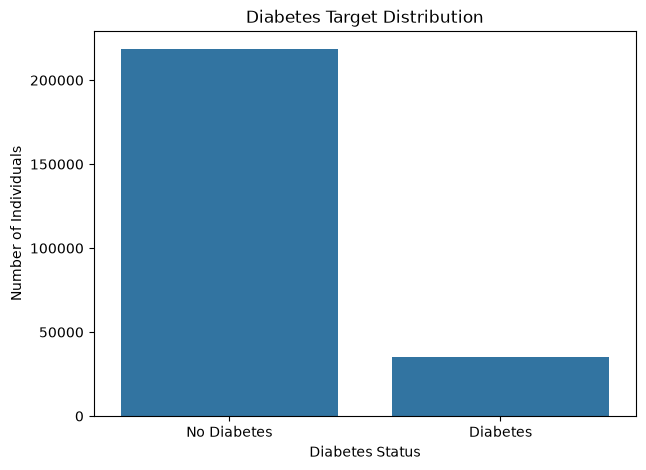

In [24]:
print(df['Diabetes_binary'].value_counts())

plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='Diabetes_binary'
)

plt.title("Diabetes Target Distribution")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Individuals")

plt.xticks([0, 1], ['No Diabetes', 'Diabetes'])

plt.show()

In [26]:
target_percentage = df['Diabetes_binary'].value_counts(normalize=True) * 100

print("Target Distribution (%):")
print(target_percentage.round(2))

Target Distribution (%):
Diabetes_binary
0.0    86.07
1.0    13.93
Name: proportion, dtype: float64


In [14]:
print("Feature Data Types:\n")
print(df.dtypes)

Feature Data Types:

Diabetes_binary         float64
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholConsump       float64
AnyHealthcare           float64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                     float64
Age                     float64
Education               float64
Income                  float64
dtype: object


In [27]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,253680.0,0.139333,0.346294,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


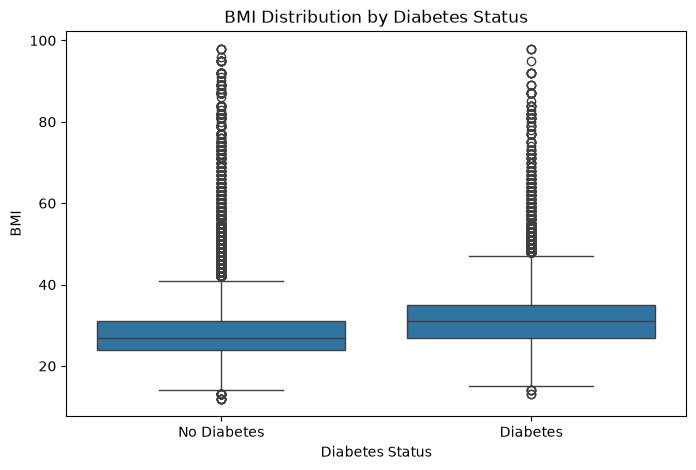

In [28]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='Diabetes_binary',
    y='BMI'
)

plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("Diabetes Status")
plt.ylabel("BMI")

plt.xticks([0,1], ['No Diabetes', 'Diabetes'])

plt.show()

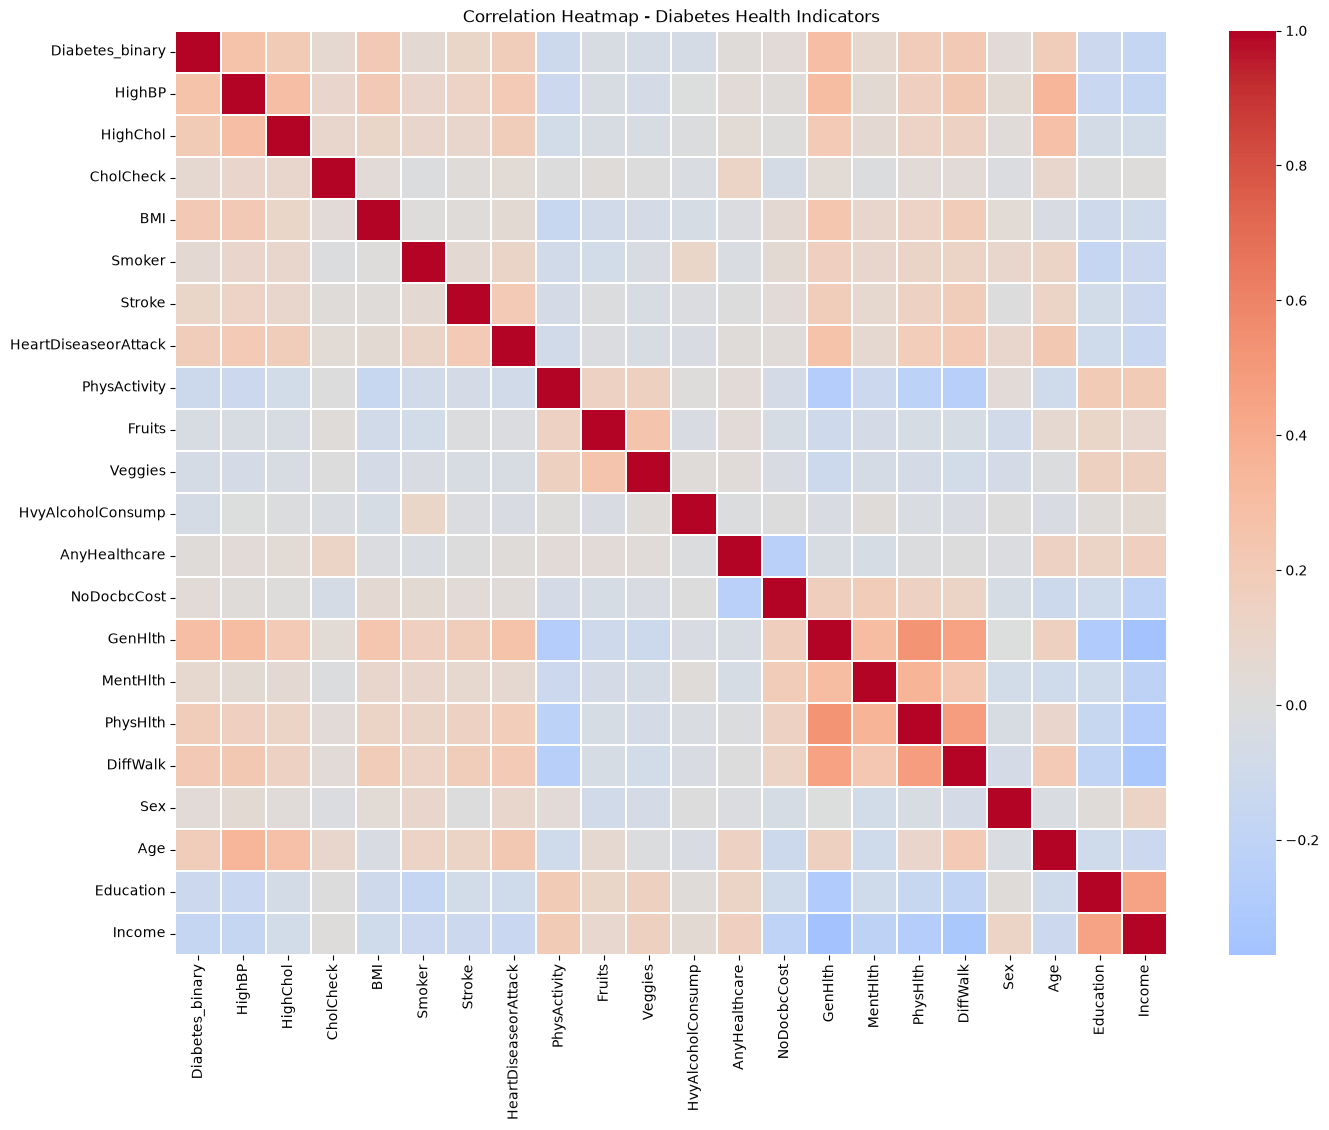

In [29]:
plt.figure(figsize=(16,12))

correlation = df.corr()

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0,
    linewidths=0.3
)

plt.title("Correlation Heatmap - Diabetes Health Indicators")

plt.show()

In [30]:
diabetes_corr = df.corr()['Diabetes_binary'].sort_values(
    ascending=False
)

print("Feature Correlation with Diabetes:\n")
display(diabetes_corr)

Feature Correlation with Diabetes:



Diabetes_binary         1.000000
GenHlth                 0.293569
HighBP                  0.263129
DiffWalk                0.218344
BMI                     0.216843
HighChol                0.200276
Age                     0.177442
HeartDiseaseorAttack    0.177282
PhysHlth                0.171337
Stroke                  0.105816
MentHlth                0.069315
CholCheck               0.064761
Smoker                  0.060789
NoDocbcCost             0.031433
Sex                     0.031430
AnyHealthcare           0.016255
Fruits                 -0.040779
Veggies                -0.056584
HvyAlcoholConsump      -0.057056
PhysActivity           -0.118133
Education              -0.124456
Income                 -0.163919
Name: Diabetes_binary, dtype: float64

In [31]:
# Count exact duplicate records

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

# Create a dataset without exact duplicates for comparison
df_unique = df.drop_duplicates()

print("Original Dataset Shape:", df.shape)
print("Unique Dataset Shape:", df_unique.shape)

print("Records Removed:", len(df) - len(df_unique))

Total Duplicate Records: 24206
Original Dataset Shape: (253680, 22)
Unique Dataset Shape: (229474, 22)
Records Removed: 24206


In [32]:
# Group identical input features and count unique target values

feature_columns = df.drop(columns=['Diabetes_binary']).columns

target_conflicts = (
    df.groupby(list(feature_columns))['Diabetes_binary']
    .nunique()
)

print("Feature Profiles:", len(target_conflicts))

print(
    "Profiles with Conflicting Diabetes Labels:",
    (target_conflicts > 1).sum()
)

Feature Profiles: 227908
Profiles with Conflicting Diabetes Labels: 1566


In [33]:
print("Minimum Values:")
display(df.min())

print("\nMaximum Values:")
display(df.max())

Minimum Values:


Diabetes_binary          0.0
HighBP                   0.0
HighChol                 0.0
CholCheck                0.0
BMI                     12.0
Smoker                   0.0
Stroke                   0.0
HeartDiseaseorAttack     0.0
PhysActivity             0.0
Fruits                   0.0
Veggies                  0.0
HvyAlcoholConsump        0.0
AnyHealthcare            0.0
NoDocbcCost              0.0
GenHlth                  1.0
MentHlth                 0.0
PhysHlth                 0.0
DiffWalk                 0.0
Sex                      0.0
Age                      1.0
Education                1.0
Income                   1.0
dtype: float64


Maximum Values:


Diabetes_binary          1.0
HighBP                   1.0
HighChol                 1.0
CholCheck                1.0
BMI                     98.0
Smoker                   1.0
Stroke                   1.0
HeartDiseaseorAttack     1.0
PhysActivity             1.0
Fruits                   1.0
Veggies                  1.0
HvyAlcoholConsump        1.0
AnyHealthcare            1.0
NoDocbcCost              1.0
GenHlth                  5.0
MentHlth                30.0
PhysHlth                30.0
DiffWalk                 1.0
Sex                      1.0
Age                     13.0
Education                6.0
Income                   8.0
dtype: float64

In [34]:
binary_columns = [
    'Diabetes_binary',
    'HighBP',
    'HighChol',
    'CholCheck',
    'Smoker',
    'Stroke',
    'HeartDiseaseorAttack',
    'PhysActivity',
    'Fruits',
    'Veggies',
    'HvyAlcoholConsump',
    'AnyHealthcare',
    'NoDocbcCost',
    'DiffWalk',
    'Sex'
]

for col in binary_columns:
    print(f"{col}: {sorted(df[col].unique())}")

Diabetes_binary: [0.0, 1.0]
HighBP: [0.0, 1.0]
HighChol: [0.0, 1.0]
CholCheck: [0.0, 1.0]
Smoker: [0.0, 1.0]
Stroke: [0.0, 1.0]
HeartDiseaseorAttack: [0.0, 1.0]
PhysActivity: [0.0, 1.0]
Fruits: [0.0, 1.0]
Veggies: [0.0, 1.0]
HvyAlcoholConsump: [0.0, 1.0]
AnyHealthcare: [0.0, 1.0]
NoDocbcCost: [0.0, 1.0]
DiffWalk: [0.0, 1.0]
Sex: [0.0, 1.0]


In [35]:
# Preserve the original dataset
df_original = df.copy()

# Remove exact duplicate records
df_cleaned = df.drop_duplicates().copy()

# Reset index
df_cleaned.reset_index(drop=True, inplace=True)

print("Original Dataset:", df_original.shape)
print("Cleaned Dataset:", df_cleaned.shape)

print("Remaining Duplicates:", df_cleaned.duplicated().sum())

Original Dataset: (253680, 22)
Cleaned Dataset: (229474, 22)
Remaining Duplicates: 0


In [36]:
print("Target Distribution After Cleaning:\n")

print(df_cleaned['Diabetes_binary'].value_counts())

print("\nPercentage Distribution:\n")

print(
    (df_cleaned['Diabetes_binary'].value_counts(normalize=True) * 100)
    .round(2)
)

Target Distribution After Cleaning:

Diabetes_binary
0.0    194377
1.0     35097
Name: count, dtype: int64

Percentage Distribution:

Diabetes_binary
0.0    84.71
1.0    15.29
Name: proportion, dtype: float64


In [37]:
X = df_cleaned.drop(columns=['Diabetes_binary'])

y = df_cleaned['Diabetes_binary']

print("Feature Matrix Shape:", X.shape)
print("Target Vector Shape:", y.shape)

Feature Matrix Shape: (229474, 21)
Target Vector Shape: (229474,)


In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training Features: (183579, 21)
Testing Features: (45895, 21)

Training Target Distribution:
Diabetes_binary
0.0    0.847
1.0    0.153
Name: proportion, dtype: float64

Testing Target Distribution:
Diabetes_binary
0.0    0.847
1.0    0.153
Name: proportion, dtype: float64


In [39]:
scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)

print("Feature Means After Scaling:")
display(scaled_df.mean().round(3))

print("\nFeature Standard Deviations:")
display(scaled_df.std().round(3))

NameError: name 'X_train_scaled' is not defined

In [40]:
from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Scale training data
X_train_scaled = scaler.fit_transform(X_train)

# Scale testing data
X_test_scaled = scaler.transform(X_test)

print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

print("Feature Scaling Completed!"
     )

Training Data Shape: (183579, 21)
Testing Data Shape: (45895, 21)
Feature Scaling Completed!


In [41]:
scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)

print("Feature Means After Scaling:")
display(scaled_df.mean().round(3))

print("\nFeature Standard Deviations:")
display(scaled_df.std().round(3))

Feature Means After Scaling:


HighBP                  0.0
HighChol                0.0
CholCheck              -0.0
BMI                    -0.0
Smoker                 -0.0
Stroke                  0.0
HeartDiseaseorAttack    0.0
PhysActivity           -0.0
Fruits                 -0.0
Veggies                -0.0
HvyAlcoholConsump      -0.0
AnyHealthcare           0.0
NoDocbcCost             0.0
GenHlth                 0.0
MentHlth                0.0
PhysHlth                0.0
DiffWalk               -0.0
Sex                    -0.0
Age                     0.0
Education              -0.0
Income                 -0.0
dtype: float64


Feature Standard Deviations:


HighBP                  1.0
HighChol                1.0
CholCheck               1.0
BMI                     1.0
Smoker                  1.0
Stroke                  1.0
HeartDiseaseorAttack    1.0
PhysActivity            1.0
Fruits                  1.0
Veggies                 1.0
HvyAlcoholConsump       1.0
AnyHealthcare           1.0
NoDocbcCost             1.0
GenHlth                 1.0
MentHlth                1.0
PhysHlth                1.0
DiffWalk                1.0
Sex                     1.0
Age                     1.0
Education               1.0
Income                  1.0
dtype: float64

In [42]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

print("Logistic Regression initialized successfully!")

Logistic Regression initialized successfully!


In [43]:
lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [44]:
y_pred_lr = lr_model.predict(X_test_scaled)

y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("LOGISTIC REGRESSION PERFORMANCE")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

LOGISTIC REGRESSION PERFORMANCE
Accuracy: 0.7143043904564768
Precision: 0.3182604545725705
Recall: 0.7600797834449352
F1 Score: 0.4486586493987049
ROC-AUC: 0.8105827554685583

Classification Report:
              precision    recall  f1-score   support

         0.0       0.94      0.71      0.81     38876
         1.0       0.32      0.76      0.45      7019

    accuracy                           0.71     45895
   macro avg       0.63      0.73      0.63     45895
weighted avg       0.85      0.71      0.75     45895



In [46]:
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

NameError: name 'confusion_matrix' is not defined

In [47]:
from sklearn.metrics import confusion_matrix

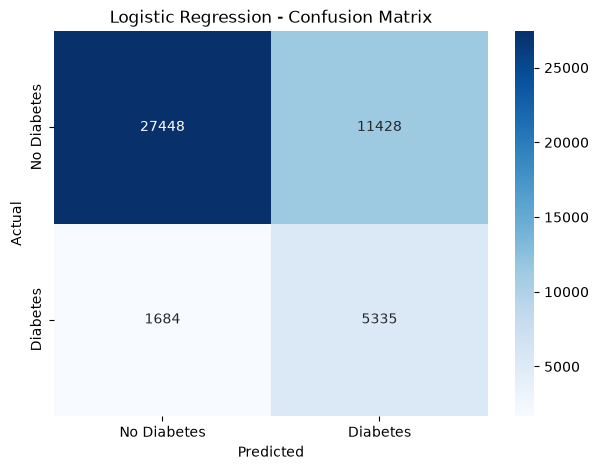

In [48]:
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [49]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=18,
    min_samples_leaf=2,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

print("Random Forest initialized successfully!")

Random Forest initialized successfully!


In [50]:
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [51]:
y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions generated successfully!")

Random Forest predictions generated successfully!


In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("RANDOM FOREST PERFORMANCE")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

RANDOM FOREST PERFORMANCE
Accuracy: 0.7874496132476304
Precision: 0.3747940691927512
Recall: 0.5834164410884741
F1 Score: 0.4563945388687657
ROC-AUC: 0.8063273581748867

Classification Report:
              precision    recall  f1-score   support

         0.0       0.92      0.82      0.87     38876
         1.0       0.37      0.58      0.46      7019

    accuracy                           0.79     45895
   macro avg       0.65      0.70      0.66     45895
weighted avg       0.83      0.79      0.80     45895



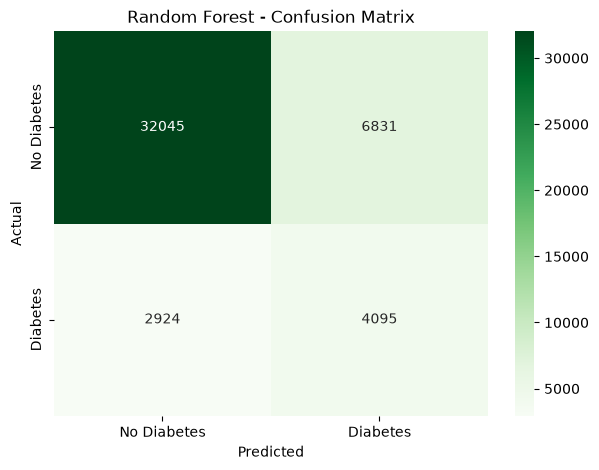

In [53]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [54]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

                 Feature  Importance
3                    BMI    0.152849
13               GenHlth    0.139701
0                 HighBP    0.123525
18                   Age    0.118004
20                Income    0.062313
15              PhysHlth    0.059634
1               HighChol    0.059291
14              MentHlth    0.047210
19             Education    0.040549
16              DiffWalk    0.034504
6   HeartDiseaseorAttack    0.021567
17                   Sex    0.020600
4                 Smoker    0.019590
8                 Fruits    0.019574
7           PhysActivity    0.018408
9                Veggies    0.016136
10     HvyAlcoholConsump    0.011749
12           NoDocbcCost    0.010675
2              CholCheck    0.008823
5                 Stroke    0.008520
11         AnyHealthcare    0.006779


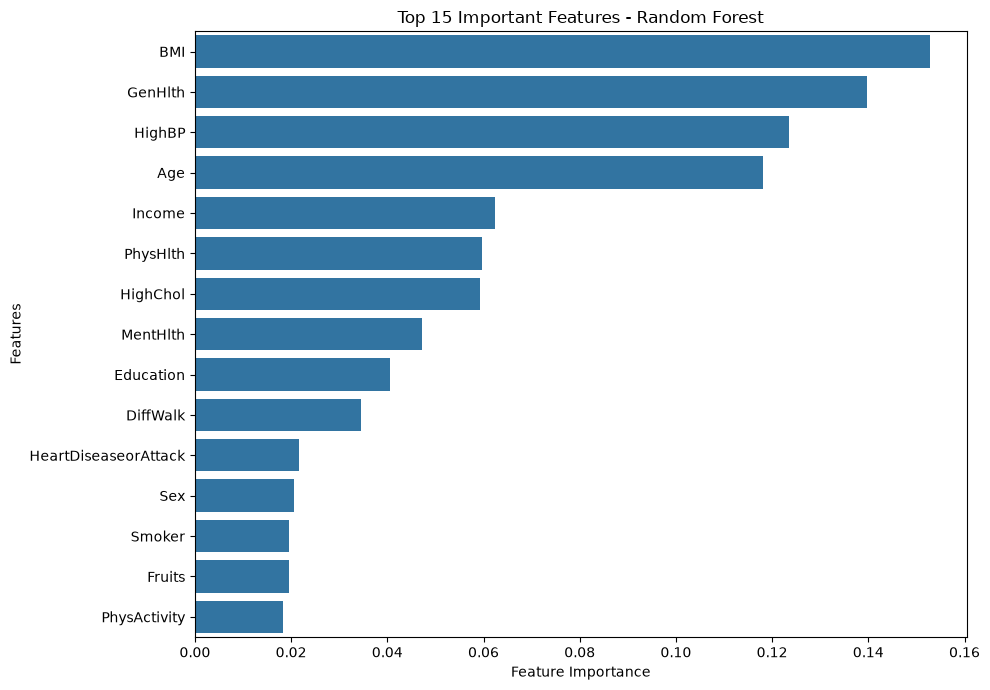

In [55]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [56]:
import shap

print("SHAP version:", shap.__version__)
print("SHAP imported successfully!")

SHAP version: 0.48.0
SHAP imported successfully!


In [57]:
X_shap = X_test.sample(
    n=300,
    random_state=42
)

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (300, 21)


In [58]:
print("X_train:", 'X_train' in globals())
print("X_test:", 'X_test' in globals())
print("rf_model:", 'rf_model' in globals())

X_train: True
X_test: True
rf_model: True


In [59]:
X_shap = X_test.sample(n=300, random_state=42)

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (300, 21)


In [62]:
explainer = shap.TreeExplainer(rf_model)

print("SHAP explainer created successfully!")

SHAP explainer created successfully!


In [63]:
X_shap = X_test.sample(n=20, random_state=42)

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (20, 21)


In [64]:
print("Calculating SHAP values...")

shap_values = explainer.shap_values(
    X_shap,
    approximate=True,
    check_additivity=False
)

print("SHAP values calculated successfully!")

Calculating SHAP values...
SHAP values calculated successfully!


In [65]:
print("SHAP output type:", type(shap_values))

if isinstance(shap_values, list):
    print("Number of classes:", len(shap_values))
    print("Positive class shape:", shap_values[1].shape)
else:
    print("SHAP shape:", shap_values.shape)

SHAP output type: <class 'numpy.ndarray'>
SHAP shape: (20, 21, 2)


In [66]:
shap_positive = shap_values[:, :, 1]

print("Positive class SHAP shape:", shap_positive.shape)

Positive class SHAP shape: (20, 21)


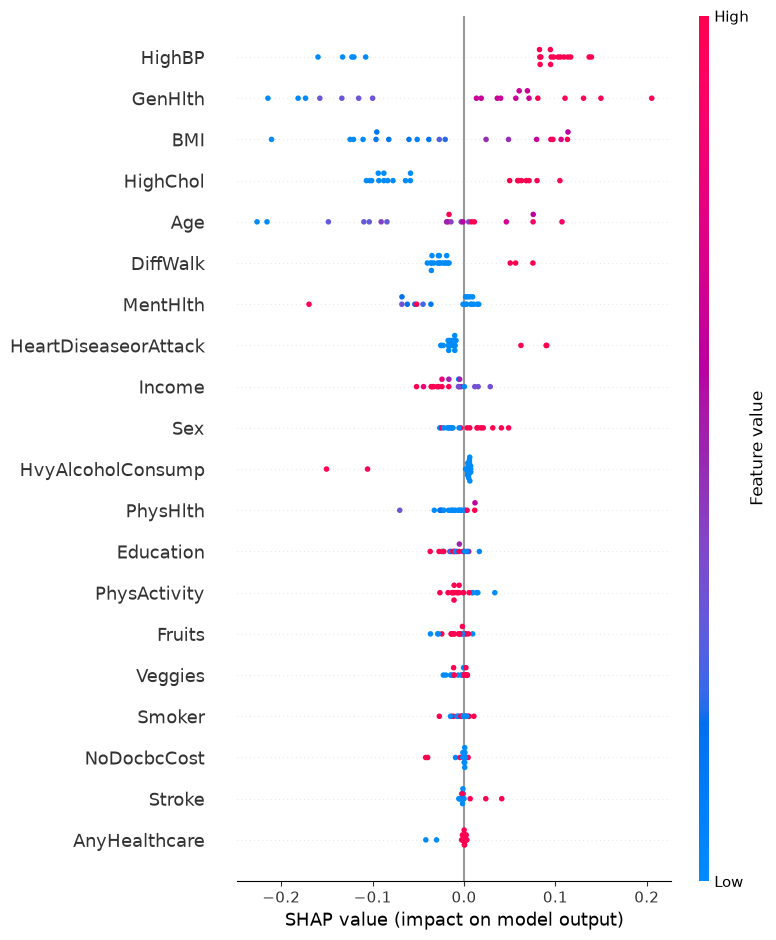

In [67]:
shap.summary_plot(
    shap_positive,
    X_shap,
    show=True
)

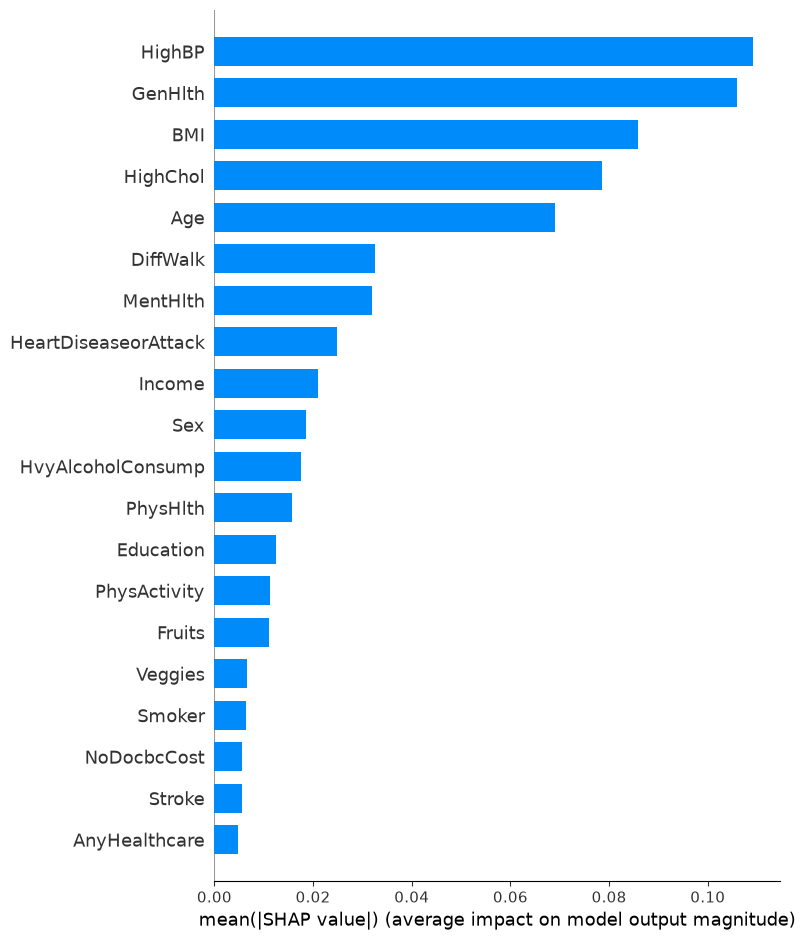

In [68]:
shap.summary_plot(
    shap_positive,
    X_shap,
    plot_type="bar",
    show=True
)

In [69]:
import joblib
import os

print("Joblib imported successfully!")

Joblib imported successfully!


In [70]:
os.makedirs("models", exist_ok=True)

print("Models folder created successfully!")

Models folder created successfully!


In [71]:
joblib.dump(rf_model, "models/random_forest_diabetes.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [72]:
joblib.dump(lr_model, "models/logistic_regression_diabetes.pkl")

joblib.dump(scaler, "models/standard_scaler.pkl")

print("Logistic Regression model and scaler saved successfully!")

Logistic Regression model and scaler saved successfully!


In [73]:
print(os.listdir("models"))

['logistic_regression_diabetes.pkl', 'random_forest_diabetes.pkl', 'standard_scaler.pkl']


In [74]:
def predict_diabetes_risk(input_data):

    input_df = pd.DataFrame(
        [input_data],
        columns=X_train.columns
    )

    prediction = rf_model.predict(input_df)[0]

    probability = rf_model.predict_proba(input_df)[0][1]

    if prediction == 1:
        result = "Higher predicted diabetes risk"
    else:
        result = "Lower predicted diabetes risk"

    return {
        "Prediction": result,
        "Estimated Probability": round(float(probability), 4)
    }

print("Prediction function created successfully!")

Prediction function created successfully!


In [75]:
sample_input = X_test.iloc[0].to_dict()

prediction_result = predict_diabetes_risk(sample_input)

print("MediSense AI Prediction:")
print(prediction_result)

MediSense AI Prediction:
{'Prediction': 'Lower predicted diabetes risk', 'Estimated Probability': 0.454}


In [76]:
print("INPUT FEATURES:")
display(pd.DataFrame([sample_input]))

print("\nPREDICTION RESULT:")
print(prediction_result)

INPUT FEATURES:


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,0.0,1.0,27.0,0.0,0.0,1.0,1.0,1.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,11.0,5.0,8.0



PREDICTION RESULT:
{'Prediction': 'Lower predicted diabetes risk', 'Estimated Probability': 0.454}


In [77]:
for i in range(5):

    sample_input = X_test.iloc[i].to_dict()

    result = predict_diabetes_risk(sample_input)

    print(f"\nPatient Sample {i+1}")
    print("Prediction:", result["Prediction"])
    print("Estimated Probability:", result["Estimated Probability"])


Patient Sample 1
Prediction: Lower predicted diabetes risk
Estimated Probability: 0.454

Patient Sample 2
Prediction: Lower predicted diabetes risk
Estimated Probability: 0.005

Patient Sample 3
Prediction: Lower predicted diabetes risk
Estimated Probability: 0.2409

Patient Sample 4
Prediction: Lower predicted diabetes risk
Estimated Probability: 0.1368

Patient Sample 5
Prediction: Lower predicted diabetes risk
Estimated Probability: 0.0856


In [78]:
loaded_rf_model = joblib.load(
    "models/random_forest_diabetes.pkl"
)

print("Saved Random Forest model loaded successfully!")

Saved Random Forest model loaded successfully!


In [79]:
sample_input = X_test.iloc[0:1]

loaded_prediction = loaded_rf_model.predict(sample_input)

loaded_probability = loaded_rf_model.predict_proba(sample_input)[0][1]

print("Prediction:", loaded_prediction[0])
print("Estimated Probability:", round(loaded_probability, 4))

Prediction: 0.0
Estimated Probability: 0.454


In [80]:
original_prediction = rf_model.predict(sample_input)[0]

loaded_prediction = loaded_rf_model.predict(sample_input)[0]

print("Original Model Prediction:", original_prediction)
print("Loaded Model Prediction:", loaded_prediction)

print(
    "Models working consistently:",
    original_prediction == loaded_prediction
)

Original Model Prediction: 0.0
Loaded Model Prediction: 0.0
Models working consistently: True


In [81]:
import os

print("Project Folder:", os.getcwd())

print("\nFiles in Project Folder:")
print(os.listdir())

Project Folder: C:\Users\divya

Files in Project Folder:
['.anaconda', '.bash_history', '.cache', '.codex', '.conda', '.condarc', '.continuum', '.copilot', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.jupyter', '.lesshst', '.matplotlib', '.mcp-auth', '.ms-ad', '.n8n', '.vscode', '.vscode-shared', '01_Diabetes_Risk_Predictionn.ipynb', '16. energy_data.csv', 'Airbnb Booking EDA', 'Airbnb_Booking_EDA.ipynb', 'AI_Energy_Efficiency_Analysis.ipynb.ipynb', 'anaconda3', 'AppData', 'Application Data', 'Common_Anomalies.csv', 'Contacts', 'Cookies', 'diabetes_binary_health_indicators_BRFSS2015.csv', 'Documents', 'Downloads', 'E-Commerce Data', 'Electricity_Forecasting_Project.ipynb', 'Energy_Project_Graphs', 'Energy_Project_Summary.csv', 'Favorites', 'Final_Anomaly_Model_Comparison.csv', 'Final_Model_Comparison.csv', 'Final_Research_Findings.csv', 'git', 'GST', 'Industrial_Energy_Anomaly_Results.csv', 'Industrial_Energy_Consumption_Analysis.csv', 'Industrial_Energy_Consumption_Analysis.ipynb